# Analysis of LSTM approach to PAWS dataset
This notebook analyses the performance of our chosen LSTM architecture on the PAWS dataset. It is intended to perform all training and other work live (assuming a GPU of at least T4-comparable capacity is present), and works with pretrained weights where that would take too long.

In [1]:
from datetime import datetime
import copy

import datasets
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import Metaspace

from sklearn.metrics import accuracy_score, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device: {device}")

device: cuda


In [2]:
ds_labeled = datasets.load_dataset("google-research-datasets/paws", "labeled_final")
ds_unlabeled = datasets.load_dataset("google-research-datasets/paws", "unlabeled_final")

README.md:   0%|          | 0.00/9.79k [00:00<?, ?B/s]

labeled_final/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 8.43MB            

labeled_final/train-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

labeled_final/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B / 1.24MB            

labeled_final/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

labeled_final/validation-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B / 1.23MB            

... (6 outputs left out)

unlabeled_final/validation-00000-of-0000(…): reconstructing file:   0%|          |  0.00B / 1.66MB            

unlabeled_final/validation-00000-of-0000(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/645652 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

In [15]:
# Hyperparams
VOCAB_SIZE = 2048
MAX_LEN = 256
BS = 32

# Preload tokenizer
tokenizer = Tokenizer.from_file("tokenizer.json")

PAD_ID = tokenizer.token_to_id("[PAD]")

# Prepare datasets
def tokenize_batch(batch):
    return {
        "ids1": [
            tokenizer.encode(s).ids
            for s in batch["sentence1"]
        ],
        "ids2": [
            tokenizer.encode(s).ids
            for s in batch["sentence2"]
        ],
    }

def collate_fn(batch): # For padding in dataloader
    def pad(sequences):
        out = torch.full(
            (len(sequences), MAX_LEN),
            PAD_ID,
            dtype=torch.long,
        )
        for i, ids in enumerate(sequences):
            out[i, :len(ids)] = torch.tensor(ids)
        return out

    x1 = pad([item["ids1"] for item in batch])
    x2 = pad([item["ids2"] for item in batch])
    y = torch.tensor(
        [item["label"] for item in batch],
        dtype=torch.long,
    )

    return x1, x2, y

encoded_unlabeled = ds_unlabeled.map(
    tokenize_batch,
    batched=True,
    remove_columns=["id", "sentence1", "sentence2"],
)

encoded_labeled = ds_labeled.map(
    tokenize_batch,
    batched=True,
    remove_columns=["id", "sentence1", "sentence2"],
)

loaders_unlabeled = {
    "train_loader": DataLoader(
        encoded_unlabeled["train"],
        batch_size=BS,
        shuffle=True,
        collate_fn=collate_fn,
    ),

    "val_loader": DataLoader(
        encoded_unlabeled["validation"],
        batch_size=BS,
        collate_fn=collate_fn,
    )
}

loaders_labeled = {
    "train_loader": DataLoader(
        encoded_labeled["train"],
        batch_size=BS,
        shuffle=True,
        collate_fn=collate_fn,
    ),

    "val_loader": DataLoader(
        encoded_labeled["validation"],
        batch_size=BS,
        collate_fn=collate_fn,
    )
}

test_loader = DataLoader(
    encoded_labeled["test"],
    batch_size=BS,
    collate_fn=collate_fn,
)


## Model architecture
The model we built intends to leverage two characteristics of the PAWS dataset: word ordering and the need for sentence comparing.

### 1. Word ordering
Some of the datapoints in the PAWS dataset can by definition never be classified correctly by a model that does not take positional ordering into account. For example, the datapoint `Glover has described Mason as Unique` $\leftrightarrow$ `Mason described Glover as Unique` in the unlabeled dataset is not a paraphrase only because of word positioning, despite containing the same words. This implies that a model that takes word order into account could perform significantly better.

A long short-term memory (LSTM) model is built to work with sequenced data by essentially taking as input the current token plus its own hidden state from processing of the previous token, making it a potentially good fit for the PAWS dataset. We leverage an LSTM here by having one LSTM model as part of the total architecture. It processes both sequences of one datapoint independently, and its final hidden states are used as input for a linear classifier.

> **Note: padding**
> Sentences are not of the same length, so in order to make tensors of their token representation the same length we need to pad the sequences using a padding token. This however yields a problem: if we use the last hidden state of our LSTM as input for the classifier, having it pass through many PAD tokens can diminish gradients. We circumvent this using `torch.nn.utils.rnn.pack_padded_sequence` which restructures batched sequences to avoid processing of PAD tokens altogether.

### 2. Sentence comparing
The final label represents whether sentences 1 and 2 are paraphrases of each other, meaning some representation of both of them needs to be compared. In order to do so, we feed our classifyer model not only the hidden LSTM states of both sentences, but also two features constructed using those, namely their absolute difference and their product. We train models both with and without these features to compare performance.


In [18]:
class DualLSTMClassifier(nn.Module):
    """
    An LSTM-based classifier purpose-built for the PAWS dataset. It consists of
    an LSTM encoder and a linear classifier applied sequentially, and takes
    a sequence of tokens as input that should be the tokenized version of a
    sentence through a tokenizer with a vocabulary of size=vocab_size.
    """
    def __init__(
        self,
        use_features=True,
        vocab_size=VOCAB_SIZE,
        pad_id=PAD_ID,
        embed_dim=128,
        lstm_hidden_dim=128,
        lstm_layers=2,
        linear_hidden_dim=128,
        dropout=.2,
    ) -> None:
        super().__init__()
        self.use_features = use_features
        self.pad_id = pad_id

        # Embedding (learned float representations of tokens)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)
        self.embedding_dropout = nn.Dropout(dropout)

        self.encoder = nn.LSTM(
            input_size=embed_dim,
            hidden_size=lstm_hidden_dim,
            batch_first=True,
            num_layers=lstm_layers,
            bidirectional=True,
            dropout=dropout
        )

        # If features are used, the input to the linear model will be larger by
        # 2 * lstm_hidden_dim, else it remains 2 * lstm_hidden_dim
        dim_multiplier = 4 if self.use_features else 2
        self.classifier = nn.Sequential(
            nn.Linear(2 * dim_multiplier * lstm_hidden_dim, linear_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(linear_hidden_dim, 2),
        )

    def _encode(self, seq):
        lengths = (seq != self.pad_id).sum(dim=1).cpu()

        emb = self.embedding(seq)
        emb = self.embedding_dropout(emb)

        # Avoid diminishing gradient through padding
        packed = nn.utils.rnn.pack_padded_sequence(
            emb,
            lengths,
            batch_first=True,
            enforce_sorted=False,
        )

        # Obtain hidden layers
        _, (h_n, _) = self.encoder(packed)

        return torch.cat([h_n[-2], h_n[-1]], dim=-1) # Bidirectional

    def forward(self, seq_1, seq_2):

        # 1. Encode both sequences (get hidden LSTM states)
        h_n_1 = self._encode(seq_1)
        h_n_2 = self._encode(seq_2)

        # Classifier input: raw hidden states plus abs diff/product features if set
        classifier_input = torch.cat(
            [
                h_n_1,
                h_n_2,
                torch.abs(h_n_1 - h_n_2),
                h_n_1 * h_n_2
            ], dim=-1
        ) if self.use_features else torch.cat([h_n_1, h_n_2], dim=-1)

        logits = self.classifier(classifier_input)

        return logits


class LSTMTrainer:
    def __init__(
        self,
        model,
        loaders,
        max_eps=30,
        patience=3,
        lr=1e-4
    ) -> None:
        self.model = model.to(device)
        self.train_loader, self.val_loader = loaders["train_loader"], loaders["val_loader"]

        self.max_eps, self.patience = max_eps, patience

        self.criterion = nn.CrossEntropyLoss()
        self.optimizer = torch.optim.AdamW(model.parameters(), lr=lr)

    def _run_epoch(self, loader, training=True):
        self.model.train(training)

        total_loss = .0
        total_correct = 0
        total = 0

        for x1, x2, y in loader:
            x1 = x1.to(device)
            x2 = x2.to(device)
            y = y.to(device)

            with torch.set_grad_enabled(training):
                logits = self.model(x1, x2)
                loss = self.criterion(logits, y)

                if training:
                    self.optimizer.zero_grad(set_to_none=True)
                    loss.backward()
                    self.optimizer.step()

            total_loss += loss.item() * y.size(0)
            total_correct += (logits.argmax(dim=1) == y).sum().item() # Accuracy
            total += y.size(0)

        return total_loss / total, total_correct / total

    def train(self):
        best_val_loss = 999
        best_weights = None
        epochs_without_improvement = 0
        prev_epoch_time = datetime.now()

        for ep in range(1, self.max_eps+1):
            train_loss, train_acc = self._run_epoch(self.train_loader, training=True)
            val_loss, val_acc = self._run_epoch(self.val_loader, training=False)

            print(
                f"Epoch {ep:02d} | "
                f"({datetime.now() - prev_epoch_time}) | "
                f"Train loss: {train_loss:.4f} | "
                f"Train acc: {train_acc:.3f} | "
                f"Val loss: {val_loss:.4f} | "
                f"Val acc: {val_acc:.3f}"
            )

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_weights = copy.deepcopy(self.model.state_dict())
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= self.patience:
                break

            prev_epoch_time = datetime.now()

        self.model.load_state_dict(best_weights)



We can see that the model size is highly dependent on the size of our embedding at larger (normal) vocabulary sizes, which is why we picked a relatively small vocabulary size:

In [16]:
for vocab_size in [2048, 4096, 8192, 16384]:
    model = DualLSTMClassifier(vocab_size=vocab_size)
    m_trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    ) / 1e6
    m_embedding_params = sum(
        p.numel() for p in model.embedding.parameters() if p.requires_grad
    ) / 1e6
    print(
        f"{m_trainable_params:.1f}M model params ",
        f"at vocab_size={vocab_size}, ",
        f"of which {m_embedding_params:.1f}M embedding params"
      )
    del model

2048 2047
1.1M model params  at vocab_size=2048,  of which 0.3M embedding params
4096 2047
1.3M model params  at vocab_size=4096,  of which 0.5M embedding params
8192 2047
1.8M model params  at vocab_size=8192,  of which 1.0M embedding params
16384 2047
2.9M model params  at vocab_size=16384,  of which 2.1M embedding params


## Training
We will now train the model on the labeled dataset, with and without the features. We will then compare metrics on test set performance for these two models and another model with the same architecture trained on the unlabeled dataset (this takes up to 3 hours to train on a T4, so we provide pretrained weights. To train it yourself, run
```python
trainer_unlabeled_feats = LSTMTrainer(
    model=DualLSTMClassifier(),
    loaders=loaders_unlabeled
)

trainer_unlabeled_feats.train()
```
We first train both labeled-dataset models, then load the pretrained model and then compare. An epoch on the labeled dataset with bs = 32 should take about 55 seconds on a T4.

In [ ]:
trainer_labeled_feats = LSTMTrainer(
    model=DualLSTMClassifier(),
    loaders=loaders_labeled,
 )

trainer_labeled_feats.train()

Epoch 01 | (0:00:53.365820) | Train loss: 0.6664 | Train acc: 0.584 | Val loss: 0.6792 | Val acc: 0.573
Epoch 02 | (0:00:52.666497) | Train loss: 0.6120 | Train acc: 0.664 | Val loss: 0.6437 | Val acc: 0.644
Epoch 03 | (0:00:52.536646) | Train loss: 0.5729 | Train acc: 0.703 | Val loss: 0.6807 | Val acc: 0.651
Epoch 04 | (0:00:52.712661) | Train loss: 0.5436 | Train acc: 0.726 | Val loss: 0.7440 | Val acc: 0.643
Epoch 05 | (0:00:53.408582) | Train loss: 0.5246 | Train acc: 0.742 | Val loss: 0.6937 | Val acc: 0.673


In [21]:
trainer_labeled_no_feats = LSTMTrainer(
    model=DualLSTMClassifier(use_features=False),
    loaders=loaders_labeled
)

trainer_labeled_no_feats.train()

Epoch 01 | (0:00:50.691495) | Train loss: 0.6859 | Train acc: 0.558 | Val loss: 0.6834 | Val acc: 0.562
Epoch 02 | (0:00:50.802723) | Train loss: 0.6795 | Train acc: 0.573 | Val loss: 0.6814 | Val acc: 0.568
Epoch 03 | (0:00:50.981726) | Train loss: 0.6718 | Train acc: 0.584 | Val loss: 0.6838 | Val acc: 0.568
Epoch 04 | (0:00:50.782070) | Train loss: 0.6612 | Train acc: 0.596 | Val loss: 0.6964 | Val acc: 0.573
Epoch 05 | (0:00:50.673488) | Train loss: 0.6454 | Train acc: 0.607 | Val loss: 0.6763 | Val acc: 0.581
Epoch 06 | (0:00:50.648223) | Train loss: 0.6272 | Train acc: 0.623 | Val loss: 0.6962 | Val acc: 0.615
Epoch 07 | (0:00:50.715766) | Train loss: 0.6105 | Train acc: 0.641 | Val loss: 0.6386 | Val acc: 0.656
Epoch 08 | (0:00:50.915479) | Train loss: 0.5903 | Train acc: 0.663 | Val loss: 0.6342 | Val acc: 0.661
Epoch 09 | (0:00:50.956408) | Train loss: 0.5750 | Train acc: 0.673 | Val loss: 0.6531 | Val acc: 0.662
Epoch 10 | (0:00:50.769410) | Train loss: 0.5581 | Train acc: 0.

In [20]:
model_labeled_feats = trainer_labeled_feats.model
model_labeled_no_feats = trainer_labeled_no_feats.model

model_unlabeled_feats = DualLSTMClassifier().to(device)
ckpt = torch.load("model_unlabeled.pth", map_location="cpu", weights_only=True)
model_unlabeled_feats.load_state_dict(ckpt["wts"])


def get_test_set_metrics(model, test_loader=test_loader):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    total = 0
    y_true = []
    y_pred = []

    with torch.no_grad():
        for x1, x2, y in test_loader:
            x1 = x1.to(device)
            x2 = x2.to(device)
            y = y.to(device)

            logits = model(x1, x2)
            loss = criterion(logits, y)

            total_loss += loss.item() * y.size(0)
            total += y.size(0)

            preds = logits.argmax(dim=1)
            y_true.extend(y.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    test_loss = total_loss / total

    test_acc = accuracy_score(y_true, y_pred)

    target_names = ["not paraphrase", "paraphrase"]

    report_text = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        digits=4
    )

    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=target_names,
        output_dict=True
    )

    return {
        "loss": test_loss,
        "acc": test_acc,
        "report": report_dict,
        "report_text": report_text
    }

NameError: name 'trainer_labeled_feats' is not defined

In [ ]:
metrics_labeled_feats = get_test_set_metrics(model_labeled_feats)
metrics_labeled_no_feats = get_test_set_metrics(model_labeled_no_feats)
metrics_unlabeled_feats = get_test_set_metrics(model_unlabeled_feats)

In [ ]:
# Labeled, features
print(
    '='*20, " Labeled, Features ", '='*20,
    f"\nTest loss: {metrics_labeled_feats['loss']:.4f}",
    f"Test accuracy: {metrics_labeled_feats['acc']:.4%}",
    '\n', metrics_labeled_feats["report_text"], '\n\n'
)

# Labeled, no features
print(
    '='*18, " Labeled, No Features ", '='*19,
    f"\nTest loss: {metrics_labeled_no_feats['loss']:.4f}",
    f"Test accuracy: {metrics_labeled_no_feats['acc']:.4%}",
    '\n', metrics_labeled_no_feats["report_text"], '\n\n'
)

# Unlabeled, features
print(
    '='*19, " Unlabeled, Features ", '='*19,
    f"\nTest loss: {metrics_unlabeled_feats['loss']:.4f}",
    f"Test accuracy: {metrics_unlabeled_feats['acc']:.4%}",
    '\n', metrics_unlabeled_feats["report_text"], '\n\n'
)

# Unlabeled, no features
print(
    '='*17, " Unlabeled, No Features ", '='*18,
    f"\nTest loss: {metrics_unlabeled_feats['loss']:.4f}",
    f"Test accuracy: {metrics_unlabeled_feats['acc']:.4%}",
    '\n', metrics_unlabeled_feats["report_text"], '\n\n'
)

====================  Labeled, Features  ==================== 
Test loss: 0.6649 Test accuracy: 63.5500% 
                 precision    recall  f1-score   support

not paraphrase     0.8123    0.4509    0.5799      4464
    paraphrase     0.5561    0.8685    0.6781      3536

      accuracy                         0.6355      8000
     macro avg     0.6842    0.6597    0.6290      8000
  weighted avg     0.6991    0.6355    0.6233      8000
 


==================  Labeled, No Features  =================== 
Test loss: 0.6398 Test accuracy: 64.4625% 
                 precision    recall  f1-score   support

not paraphrase     0.6926    0.6530    0.6722      4464
    paraphrase     0.5914    0.6340    0.6120      3536

      accuracy                         0.6446      8000
     macro avg     0.6420    0.6435    0.6421      8000
  weighted avg     0.6478    0.6446    0.6456      8000
 


===================  Unlabeled, Features  =================== 
Test loss: 0.5221 Test accuracy: 85.162

We will now perform a K-fold cross validation on the labelled dataset only, with and without the added features.

Resuming results from lstm_cv_5fold_seed42.json

Fold 2/5 | without_features
Epoch 01 | (0:00:45.964085) | Train loss: 0.6861 | Train acc: 0.558 | Val loss: 0.6845 | Val acc: 0.563
Epoch 02 | (0:00:45.968634) | Train loss: 0.6807 | Train acc: 0.570 | Val loss: 0.6826 | Val acc: 0.576
Epoch 03 | (0:00:46.238569) | Train loss: 0.6736 | Train acc: 0.583 | Val loss: 0.6745 | Val acc: 0.582
Epoch 04 | (0:00:45.886540) | Train loss: 0.6661 | Train acc: 0.593 | Val loss: 0.6698 | Val acc: 0.582
Epoch 05 | (0:00:47.004012) | Train loss: 0.6561 | Train acc: 0.604 | Val loss: 0.6712 | Val acc: 0.589
Epoch 06 | (0:00:46.174379) | Train loss: 0.6412 | Train acc: 0.617 | Val loss: 0.6479 | Val acc: 0.606
Epoch 07 | (0:00:46.004376) | Train loss: 0.6229 | Train acc: 0.631 | Val loss: 0.6430 | Val acc: 0.629
Epoch 08 | (0:00:46.434002) | Train loss: 0.6045 | Train acc: 0.653 | Val loss: 0.6366 | Val acc: 0.654
Epoch 09 | (0:00:45.496985) | Train loss: 0.5875 | Train acc: 0.667 | Val loss: 0.6334 | Va

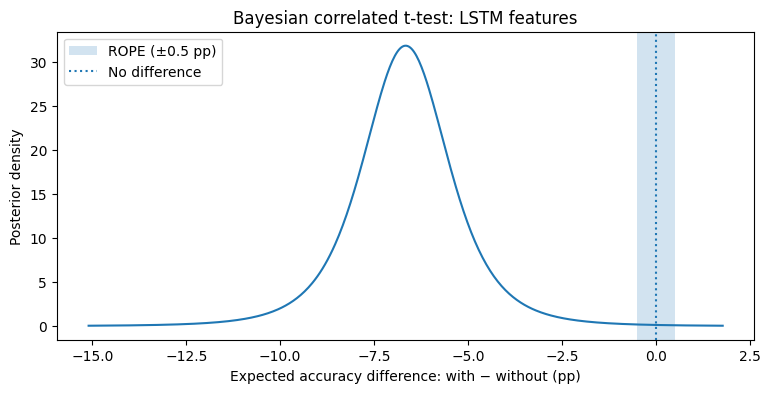

In [ ]:
K = 5
SEED = 42
INNER_VAL_FRACTION = 0.10

SYSTEMS = {
    "with_features": True,
    "without_features": False,
}
SAVE_TO = Path(f"lstm_cv_{K}fold_seed{SEED}.json")

# Combine official train + validation, but NOT test.
cv_data = datasets.concatenate_datasets([
    encoded_labeled["train"],
    encoded_labeled["validation"],
])
y_all = np.asarray(cv_data["label"], dtype=int)

settings = {
    "k": K, "seed": SEED,
    "inner_val_fraction": INNER_VAL_FRACTION,
    "batch_size": BS, "vocab_size": VOCAB_SIZE,
    "max_len": MAX_LEN, "max_epochs": 30,
    "patience": 3, "learning_rate": 1e-4,
    "n_examples": len(cv_data),
}

saved = {
    "settings": settings,
    "accuracies": {name: [None] * K for name in SYSTEMS},
}

outer_cv = StratifiedKFold(
    n_splits=K, shuffle=True, random_state=SEED
)

def make_loader(indices, shuffle=False):
    subset = cv_data.select(np.asarray(indices).tolist())
    return DataLoader(
        subset,
        batch_size=BS,
        shuffle=shuffle,
        collate_fn=collate_fn,
    )

for fold, (training_pool, outer_eval) in enumerate(
    outer_cv.split(np.zeros(len(y_all)), y_all)
):
    train_ids, early_stop_ids = train_test_split(
        training_pool,
        test_size=INNER_VAL_FRACTION,
        random_state=SEED + fold,
        stratify=y_all[training_pool],
    )

    fold_loaders = {
        "train_loader": make_loader(train_ids, shuffle=True),
        "val_loader": make_loader(early_stop_ids),
    }
    outer_loader = make_loader(outer_eval)

    for name, use_features in SYSTEMS.items():
        run_seed = SEED + fold
        random.seed(run_seed)
        np.random.seed(run_seed)
        torch.manual_seed(run_seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(run_seed)

        print(f"\nFold {fold + 1}/{K} | {name}")

        cv_model = DualLSTMClassifier(
            use_features=use_features
        )
        trainer = LSTMTrainer(
            model=cv_model,
            loaders=fold_loaders,
        )
        trainer.train()

        name_model = f"unlabeled_fold_{fold}_no_feats.pth" if use_features == True else f"unlabeled_fold_{fold}_feats.pth"
        torch.save({"wts": trainer.model.state_dict()}, "model_unlabeled_feats.pth")

        # Eval
        _, outer_accuracy = trainer._run_epoch(
            outer_loader, training=False
        )

        saved["accuracies"][name][fold] = float(outer_accuracy)

        print(f"Outer accuracy: {outer_accuracy:.4%}")

        temp_path = SAVE_TO.with_suffix(".tmp")
        temp_path.write_text(json.dumps(saved, indent=2))
        temp_path.replace(SAVE_TO)

        del trainer, cv_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

acc_no = np.asarray(
    saved["accuracies"]["without_features"], dtype=float
)
acc_yes = np.asarray(
    saved["accuracies"]["with_features"], dtype=float
)

print("\n--- Cross-validation results ---")
for i, (a, b) in enumerate(zip(acc_no, acc_yes), start=1):
    print(
        f"Fold {i}: without={a:.4%}, with={b:.4%}, "
        f"difference={(b-a)*100:+.3f} pp"
    )

print(f"Mean without: {acc_no.mean():.4%}")
print(f"Mean with:    {acc_yes.mean():.4%}")
